In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(
    "../data/crimes_features.csv"
)

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce'
)

print("Shape:", df.shape)
print("Start:", df['date'].min())
print("End:", df['date'].max())

Shape: (1388164, 27)
Start: 2021-01-01 00:00:00
End: 2026-10-03 00:00:00


In [3]:
print(df.columns.tolist())
df.head(5)

['id', 'date', 'primary_type', 'description', 'location_description', 'arrest', 'domestic', 'beat', 'district', 'ward', 'community_area', 'year', 'latitude', 'longitude', 'hour', 'day_of_week', 'month', 'month_name', 'season', 'year_month', 'day_num', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos']


,id,date,primary_type,description,location_description,arrest,domestic,beat,district,ward,...,month_name,season,year_month,day_num,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos
0,25699,2021-01-01 03:48:00,HOMICIDE,FIRST DEGREE MURDER,AUTO,False,False,224,2,3.0,...,January,Winter,2021-01,4,0.707107,7.071068e-01,-0.433884,-0.900969,0.0,1.0
1,25700,2021-01-01 18:06:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,1532,15,28.0,...,January,Winter,2021-01,4,-1.000000,-1.836970e-16,-0.433884,-0.900969,0.0,1.0
2,25701,2021-01-02 21:55:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,1022,10,24.0,...,January,Winter,2021-01,5,-0.707107,7.071068e-01,-0.974928,-0.222521,0.0,1.0
3,25702,2021-01-03 20:09:00,HOMICIDE,FIRST DEGREE MURDER,STREET,False,False,332,3,5.0,...,January,Winter,2021-01,6,-0.866025,5.000000e-01,-0.781831,0.623490,0.0,1.0
4,25703,2021-01-03 21:28:00,HOMICIDE,FIRST DEGREE MURDER,APARTMENT,True,False,424,4,10.0,...,January,Winter,2021-01,6,-0.707107,7.071068e-01,-0.781831,0.623490,0.0,1.0


In [4]:
possible_columns = [
    'primary_type',
    'description',
    'iucr'
]

for col in possible_columns:
    if col in df.columns:

        print(
            "\nCOLUMN:",
            col
        )

        print(
            df[col]
            .value_counts()
            .head(20)
        )



COLUMN: primary_type
primary_type
THEFT                               307020
BATTERY                             247089
CRIMINAL DAMAGE                     156492
ASSAULT                             124873
MOTOR VEHICLE THEFT                 114135
DECEPTIVE PRACTICE                   94790
OTHER OFFENSE                        90196
BURGLARY                             50518
ROBBERY                              46485
WEAPONS VIOLATION                    43572
NARCOTICS                            34008
CRIMINAL TRESPASS                    26820
OFFENSE INVOLVING CHILDREN           10529
CRIMINAL SEXUAL ASSAULT              10097
SEX OFFENSE                           7675
PUBLIC PEACE VIOLATION                5232
INTERFERENCE WITH PUBLIC OFFICER      3690
HOMICIDE                              3558
STALKING                              2948
ARSON                                 2610
Name: count, dtype: int64

COLUMN: description
description
SIMPLE                                 166036


In [5]:
crime_counts = (
    df['primary_type']
    .value_counts()
)

print(
    "Number of crime types:",
    crime_counts.size
)

crime_counts.head(20)

Number of crime types: 31


primary_type
THEFT                               307020
BATTERY                             247089
CRIMINAL DAMAGE                     156492
ASSAULT                             124873
MOTOR VEHICLE THEFT                 114135
DECEPTIVE PRACTICE                   94790
OTHER OFFENSE                        90196
BURGLARY                             50518
ROBBERY                              46485
WEAPONS VIOLATION                    43572
NARCOTICS                            34008
CRIMINAL TRESPASS                    26820
OFFENSE INVOLVING CHILDREN           10529
CRIMINAL SEXUAL ASSAULT              10097
SEX OFFENSE                           7675
PUBLIC PEACE VIOLATION                5232
INTERFERENCE WITH PUBLIC OFFICER      3690
HOMICIDE                              3558
STALKING                              2948
ARSON                                 2610
Name: count, dtype: int64

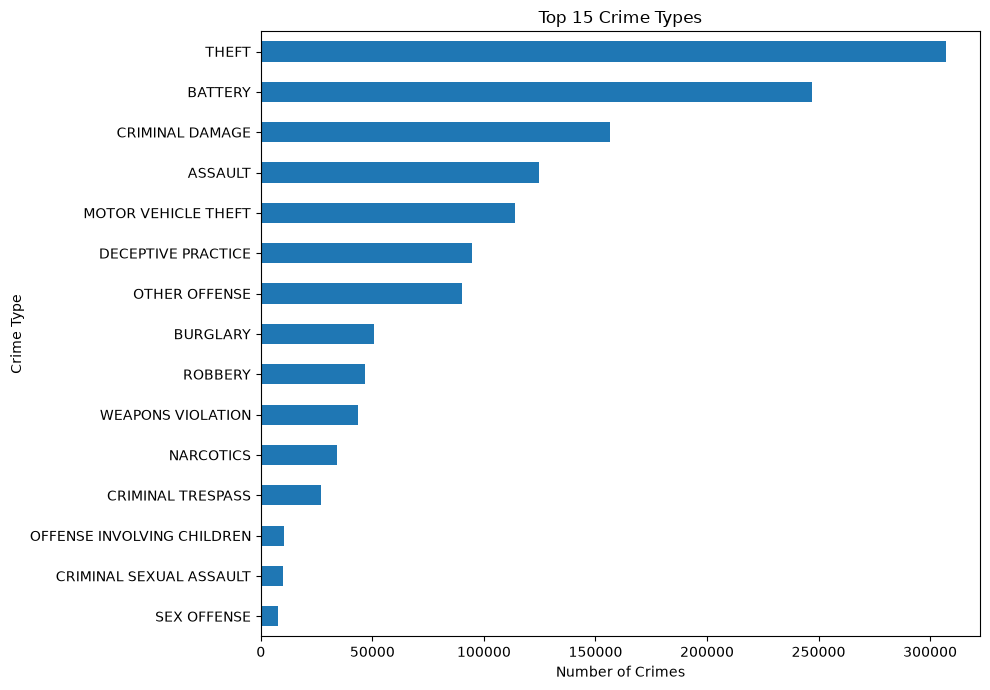

In [6]:
top_15 = (
    crime_counts
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 7))

top_15.plot(
    kind='barh'
)

plt.title('Top 15 Crime Types')
plt.xlabel('Number of Crimes')
plt.ylabel('Crime Type')

plt.tight_layout()
plt.show()


In [7]:
df['week'] = (
    df['date']
    .dt.to_period('W')
    .dt.start_time
)

In [8]:
weekly_type = (
    df
    .groupby(
        ['week', 'primary_type']
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

weekly_type.head()

,week,primary_type,crime_count
0,2020-12-28,ARSON,2
1,2020-12-28,ASSAULT,106
2,2020-12-28,BATTERY,352
3,2020-12-28,BURGLARY,52
4,2020-12-28,CONCEALED CARRY LICENSE VIOLATION,2


In [9]:
top_types = (
    df['primary_type']
    .value_counts()
    .head(10)
    .index
    .tolist()
)

top_types

['THEFT',
 'BATTERY',
 'CRIMINAL DAMAGE',
 'ASSAULT',
 'MOTOR VEHICLE THEFT',
 'DECEPTIVE PRACTICE',
 'OTHER OFFENSE',
 'BURGLARY',
 'ROBBERY',
 'WEAPONS VIOLATION']

In [10]:
weekly_top = (
    weekly_type[
        weekly_type['primary_type']
        .isin(top_types)
    ]
    .copy()
)

print(weekly_top.shape)

(3010, 3)


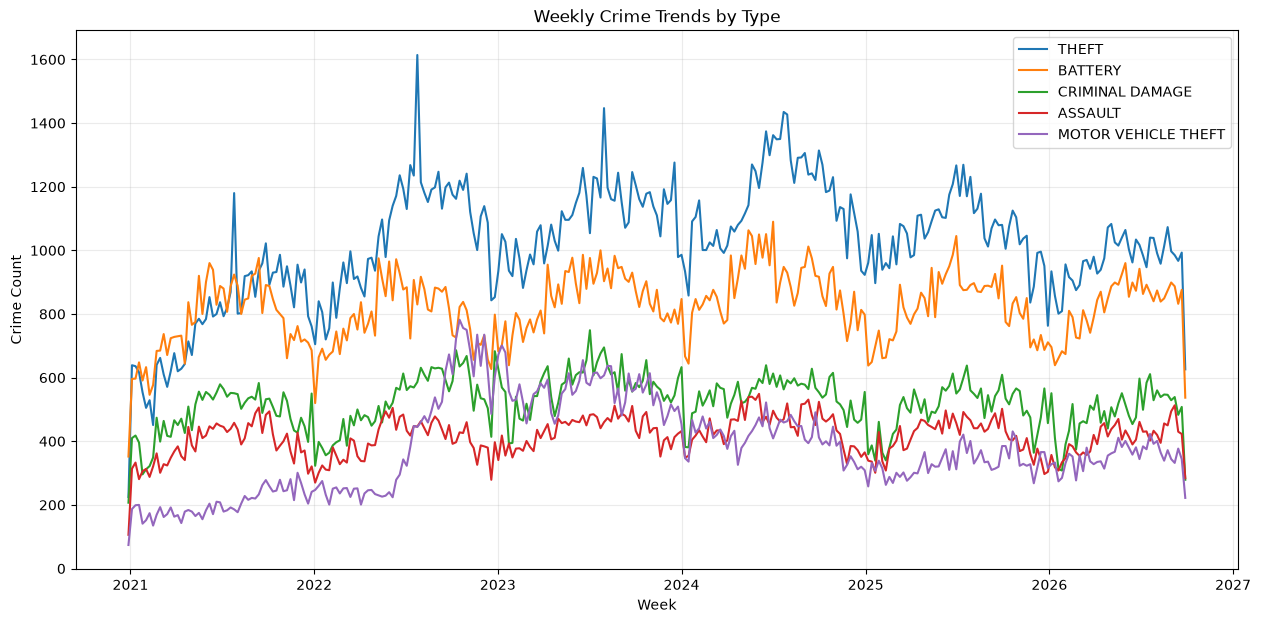

In [11]:
top_5_types = top_types[:5]

plt.figure(figsize=(15, 7))

for crime_type in top_5_types:

    temp = weekly_top[
        weekly_top['primary_type']
        == crime_type
    ]

    plt.plot(
        temp['week'],
        temp['crime_count'],
        label=crime_type
    )

plt.title(
    'Weekly Crime Trends by Type'
)

plt.xlabel('Week')
plt.ylabel('Crime Count')

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [12]:
monthly_type = (
    df[
        df['primary_type']
        .isin(top_types)
    ]
    .groupby(
        ['month', 'primary_type']
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

In [13]:
monthly_pivot = (
    monthly_type
    .pivot(
        index='month',
        columns='primary_type',
        values='crime_count'
    )
    .fillna(0)
)

monthly_pivot

primary_type,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,OTHER OFFENSE,ROBBERY,THEFT,WEAPONS VIOLATION
month,,,,,,,,,,
1,9077,18189,3690,11524,9631,9167,7736,3958,22769,3442
2,8830,17525,3253,10365,7993,8136,7362,3066,21229,3061
3,10112,20578,3958,12956,8751,8886,8294,3281,24622,3658
4,10701,20942,4135,12999,8066,8423,7970,3292,24292,3736
5,11997,23794,4724,13910,8059,9126,8224,3662,27167,4307
6,11791,23786,4577,14447,8178,9716,8089,3964,28440,4276
7,12053,23938,4812,15703,8169,10610,8270,4395,30795,4695
8,11903,23291,4931,15177,8170,10824,7654,4489,29802,4136
9,12067,23222,5001,14397,7863,10496,7956,4433,28158,3956


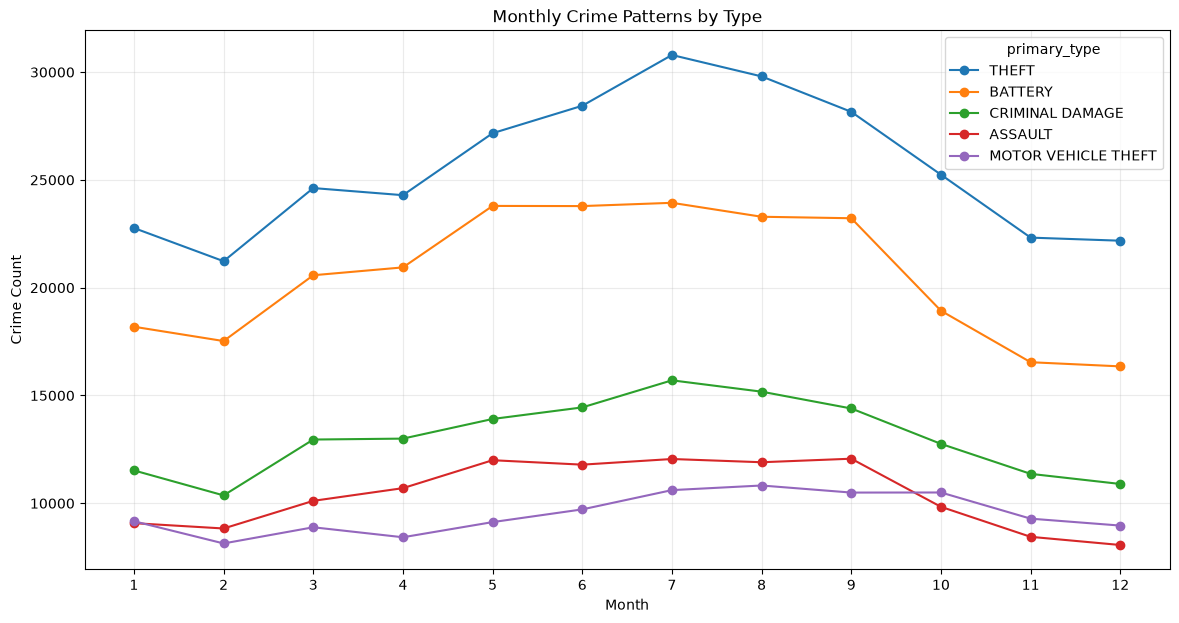

In [14]:
monthly_pivot[
    top_5_types
].plot(
    figsize=(14, 7),
    marker='o'
)

plt.title(
    'Monthly Crime Patterns by Type'
)

plt.xlabel('Month')
plt.ylabel('Crime Count')

plt.xticks(
    range(1, 13)
)

plt.grid(alpha=0.25)

plt.show()

In [15]:
weekday_type = (
    df[
        df['primary_type']
        .isin(top_types)
    ]
    .groupby(
        ['day_num', 'primary_type']
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

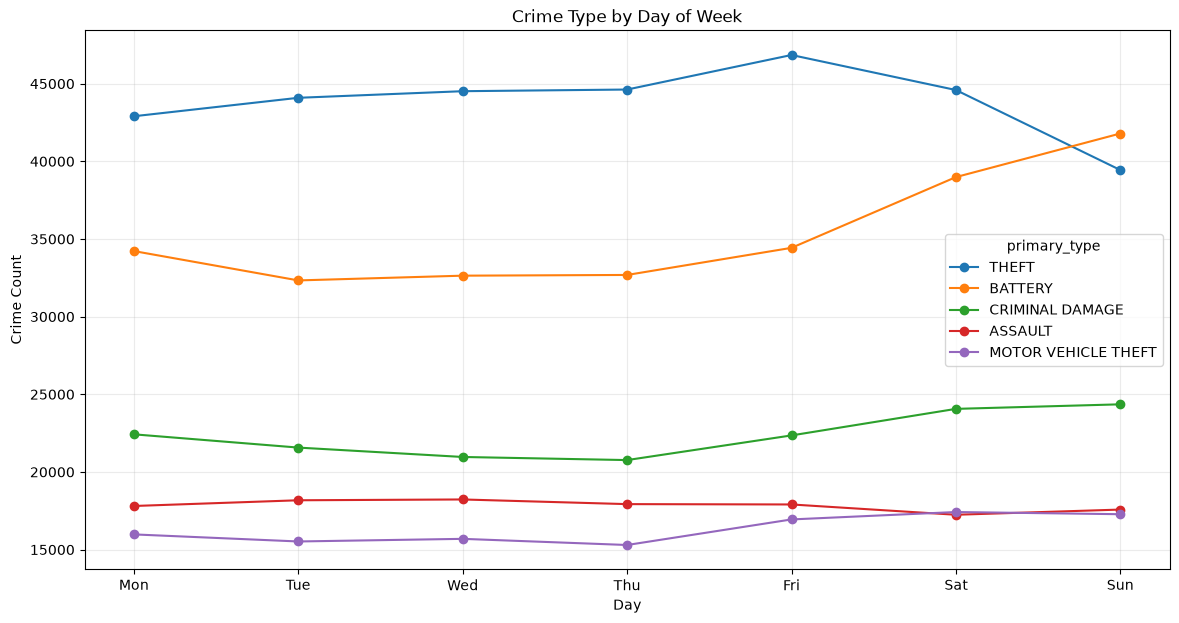

In [16]:
weekday_pivot = (
    weekday_type
    .pivot(
        index='day_num',
        columns='primary_type',
        values='crime_count'
    )
    .fillna(0)
)

weekday_pivot[
    top_5_types
].plot(
    figsize=(14, 7),
    marker='o'
)

plt.title(
    'Crime Type by Day of Week'
)

plt.xlabel('Day')
plt.ylabel('Crime Count')

plt.xticks(
    range(7),
    [
        'Mon',
        'Tue',
        'Wed',
        'Thu',
        'Fri',
        'Sat',
        'Sun'
    ]
)

plt.grid(alpha=0.25)

plt.show()


In [17]:
hourly_type = (
    df[
        df['primary_type']
        .isin(top_types)
    ]
    .groupby(
        ['hour', 'primary_type']
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

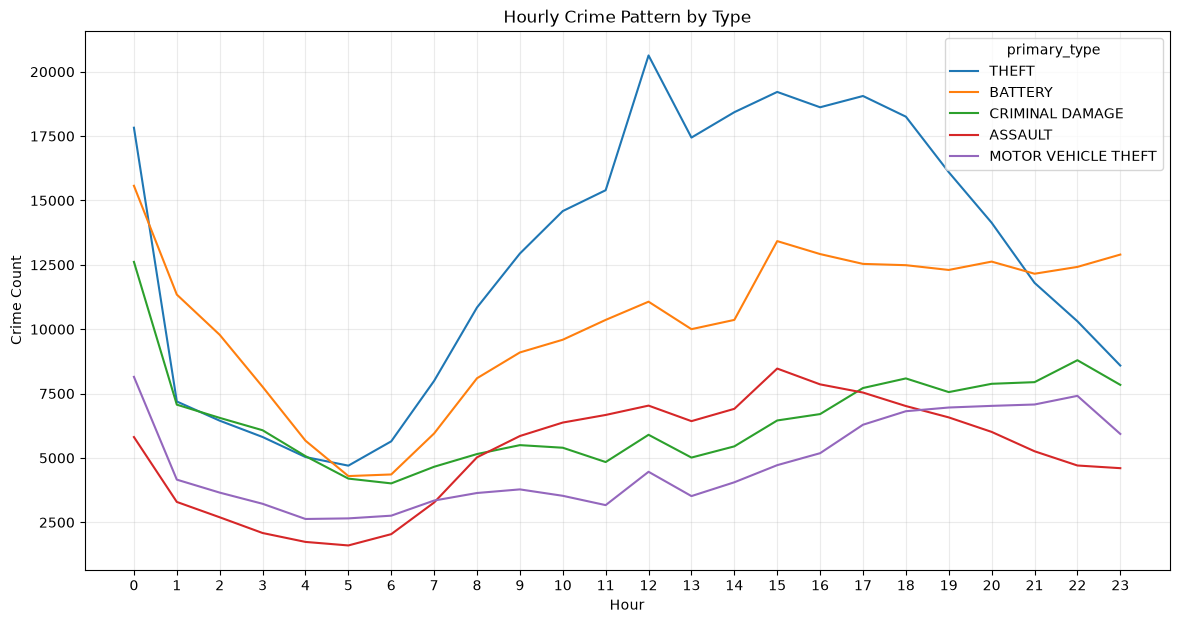

In [18]:
hourly_pivot = (
    hourly_type
    .pivot(
        index='hour',
        columns='primary_type',
        values='crime_count'
    )
    .fillna(0)
)

hourly_pivot[
    top_5_types
].plot(
    figsize=(14, 7)
)

plt.title(
    'Hourly Crime Pattern by Type'
)

plt.xlabel('Hour')
plt.ylabel('Crime Count')

plt.xticks(range(24))
plt.grid(alpha=0.25)

plt.show()

In [19]:
crime_spatial = (
    df
    .dropna(
        subset=[
            'latitude',
            'longitude',
            'primary_type'
        ]
    )
    .copy()
)

crime_spatial['grid_lat'] = (
    crime_spatial['latitude']
    .round(2)
)

crime_spatial['grid_lon'] = (
    crime_spatial['longitude']
    .round(2)
)

crime_spatial['grid_id'] = (
    crime_spatial['grid_lat']
    .astype(str)
    + "_"
    + crime_spatial['grid_lon']
    .astype(str)
)

In [20]:
area_type = (
    crime_spatial[
        crime_spatial['primary_type']
        .isin(top_types)
    ]
    .groupby(
        ['grid_id', 'primary_type']
    )
    .size()
    .reset_index(
        name='crime_count'
    )
)

area_type.head()

,grid_id,primary_type,crime_count
0,36.62_-91.69,DECEPTIVE PRACTICE,1
1,36.62_-91.69,ROBBERY,1
2,41.64_-87.54,BATTERY,1
3,41.64_-87.54,CRIMINAL DAMAGE,1
4,41.64_-87.54,MOTOR VEHICLE THEFT,2


In [21]:
dominant_type = (
    area_type
    .sort_values(
        'crime_count',
        ascending=False
    )
    .drop_duplicates(
        'grid_id'
    )
    .reset_index(drop=True)
)

dominant_type.head(20)

,grid_id,primary_type,crime_count
0,41.88_-87.63,THEFT,8821
1,41.89_-87.63,THEFT,8100
2,41.89_-87.62,THEFT,4876
3,41.9_-87.63,THEFT,4708
4,41.94_-87.65,THEFT,3575
5,41.87_-87.63,THEFT,3293
6,41.89_-87.65,THEFT,3093
7,41.91_-87.65,THEFT,2650
8,41.8_-87.59,THEFT,2491
9,41.88_-87.62,THEFT,2468


In [22]:
grid_coordinates = (
    crime_spatial
    .groupby('grid_id')
    [['grid_lat', 'grid_lon']]
    .first()
    .reset_index()
)

dominant_type = (
    dominant_type
    .merge(
        grid_coordinates,
        on='grid_id',
        how='left'
    )
)

dominant_type.head()

,grid_id,primary_type,crime_count,grid_lat,grid_lon
0,41.88_-87.63,THEFT,8821,41.88,-87.63
1,41.89_-87.63,THEFT,8100,41.89,-87.63
2,41.89_-87.62,THEFT,4876,41.89,-87.62
3,41.9_-87.63,THEFT,4708,41.90,-87.63
4,41.94_-87.65,THEFT,3575,41.94,-87.65


In [23]:
weekly_type.to_csv(
    "../data/weekly_crime_types.csv",
    index=False
)

dominant_type.to_csv(
    "../data/dominant_crime_type_by_area.csv",
    index=False
)

print("Crime-type analysis saved ✅")

Crime-type analysis saved ✅


In [24]:
weeks = pd.date_range(
    df['week'].min(),
    df['week'].max(),
    freq='7D'
)

full_index = pd.MultiIndex.from_product(
    [weeks, top_types],
    names=['week', 'primary_type']
)

weekly_complete = (
    weekly_type
    .set_index(['week', 'primary_type'])
    .reindex(full_index, fill_value=0)
    .reset_index()
)

weekly_complete = weekly_complete.sort_values(
    ['primary_type', 'week']
).reset_index(drop=True)

weekly_complete.head()

,week,primary_type,crime_count
0,2020-12-28,ASSAULT,106
1,2021-01-04,ASSAULT,314
2,2021-01-11,ASSAULT,333
3,2021-01-18,ASSAULT,281
4,2021-01-25,ASSAULT,306


In [25]:
weekly_complete['week_of_year'] = (
    weekly_complete['week']
    .dt.isocalendar()
    .week
    .astype(int)
)

weekly_complete['month'] = (
    weekly_complete['week'].dt.month
)

weekly_complete['year'] = (
    weekly_complete['week'].dt.year
)

weekly_complete['week_sin'] = np.sin(
    2 * np.pi
    * weekly_complete['week_of_year']
    / 52
)

weekly_complete['week_cos'] = np.cos(
    2 * np.pi
    * weekly_complete['week_of_year']
    / 52
)

In [26]:
grouped = weekly_complete.groupby(
    'primary_type'
)['crime_count']

weekly_complete['lag_1'] = grouped.shift(1)
weekly_complete['lag_2'] = grouped.shift(2)
weekly_complete['lag_4'] = grouped.shift(4)
weekly_complete['lag_8'] = grouped.shift(8)
weekly_complete['lag_12'] = grouped.shift(12)
weekly_complete['lag_52'] = grouped.shift(52)

In [27]:
weekly_complete['rolling_4_mean'] = (
    weekly_complete
    .groupby('primary_type')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(4)
             .mean()
    )
)

weekly_complete['rolling_8_mean'] = (
    weekly_complete
    .groupby('primary_type')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(8)
             .mean()
    )
)

weekly_complete['rolling_12_mean'] = (
    weekly_complete
    .groupby('primary_type')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(12)
             .mean()
    )
)

weekly_complete['rolling_4_std'] = (
    weekly_complete
    .groupby('primary_type')['crime_count']
    .transform(
        lambda x:
            x.shift(1)
             .rolling(4)
             .std()
    )
)

In [28]:
type_mapping = {
    crime_type: i
    for i, crime_type
    in enumerate(top_types)
}

weekly_complete['type_code'] = (
    weekly_complete['primary_type']
    .map(type_mapping)
)

In [29]:
type_model_data = (
    weekly_complete
    .dropna()
    .copy()
)

features_type = [
    'type_code',

    'week_of_year',
    'month',
    'year',

    'week_sin',
    'week_cos',

    'lag_1',
    'lag_2',
    'lag_4',
    'lag_8',
    'lag_12',
    'lag_52',

    'rolling_4_mean',
    'rolling_8_mean',
    'rolling_12_mean',
    'rolling_4_std'
]

X_type = type_model_data[
    features_type
]

y_type = type_model_data[
    'crime_count'
]

print("X:", X_type.shape)
print("y:", y_type.shape)

X: (2490, 16)
y: (2490,)


In [30]:
unique_weeks = np.sort(
    type_model_data['week'].unique()
)

split_idx = int(
    len(unique_weeks) * 0.8
)

split_week = unique_weeks[split_idx]

train_mask = (
    type_model_data['week']
    < split_week
)

test_mask = (
    type_model_data['week']
    >= split_week
)

X_train = X_type.loc[train_mask]
X_test = X_type.loc[test_mask]

y_train = y_type.loc[train_mask]
y_test = y_type.loc[test_mask]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print(
    "Train period:",
    type_model_data.loc[
        train_mask,
        'week'
    ].min(),
    "→",
    type_model_data.loc[
        train_mask,
        'week'
    ].max()
)

print(
    "Test period:",
    type_model_data.loc[
        test_mask,
        'week'
    ].min(),
    "→",
    type_model_data.loc[
        test_mask,
        'week'
    ].max()
)

Train: (1990, 16)
Test: (500, 16)
Train period: 2021-12-27 00:00:00 → 2025-10-13 00:00:00
Test period: 2025-10-20 00:00:00 → 2026-09-28 00:00:00


In [31]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline = type_model_data.loc[
    test_mask,
    'lag_1'
].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline
)

print("BASELINE")
print("----------------")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²:   {baseline_r2:.4f}")

BASELINE
----------------
MAE:  35.12
RMSE: 51.59
R²:   0.9655


In [32]:
from sklearn.ensemble import (
    HistGradientBoostingRegressor
)

crime_type_model = (
    HistGradientBoostingRegressor(
        loss='poisson',
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
)

crime_type_model.fit(
    X_train,
    y_train
)

print("Crime-type model trained ✅")

Crime-type model trained ✅


In [33]:
type_pred = crime_type_model.predict(
    X_test
)

type_pred = np.maximum(
    type_pred,
    0
)

In [34]:
model_mae = mean_absolute_error(
    y_test,
    type_pred
)

model_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        type_pred
    )
)

model_r2 = r2_score(
    y_test,
    type_pred
)

print("CRIME TYPE MODEL")
print("----------------")
print(f"MAE:  {model_mae:.2f}")
print(f"RMSE: {model_rmse:.2f}")
print(f"R²:   {model_r2:.4f}")

CRIME TYPE MODEL
----------------
MAE:  34.01
RMSE: 50.75
R²:   0.9666


In [35]:
comparison = pd.DataFrame({
    'Model': [
        'Previous Week Baseline',
        'HistGradientBoosting'
    ],

    'MAE': [
        baseline_mae,
        model_mae
    ],

    'RMSE': [
        baseline_rmse,
        model_rmse
    ],

    'R2': [
        baseline_r2,
        model_r2
    ]
})

comparison

,Model,MAE,RMSE,R2
0,Previous Week Baseline,35.118000,51.593701,0.965480
1,HistGradientBoosting,34.011934,50.751605,0.966598


In [36]:
all_weeks = np.sort(
    type_model_data['week'].unique()
)

n_folds = 4

week_blocks = np.array_split(
    all_weeks,
    n_folds + 1
)

cv_results = []


In [37]:
for fold in range(1, n_folds + 1):

    train_weeks = np.concatenate(
        week_blocks[:fold]
    )

    val_weeks = week_blocks[fold]

    train_mask_cv = (
        type_model_data['week']
        .isin(train_weeks)
    )

    val_mask_cv = (
        type_model_data['week']
        .isin(val_weeks)
    )

    X_train_cv = X_type.loc[
        train_mask_cv
    ]

    y_train_cv = y_type.loc[
        train_mask_cv
    ]

    X_val_cv = X_type.loc[
        val_mask_cv
    ]

    y_val_cv = y_type.loc[
        val_mask_cv
    ]

    model_cv = HistGradientBoostingRegressor(
        loss='poisson',
        learning_rate=0.05,
        max_iter=300,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )

    model_cv.fit(
        X_train_cv,
        y_train_cv
    )

    pred_cv = model_cv.predict(
        X_val_cv
    )

    pred_cv = np.maximum(
        pred_cv,
        0
    )

    baseline_cv = (
        type_model_data.loc[
            val_mask_cv,
            'lag_1'
        ].values
    )

    cv_results.append({
        'fold': fold,

        'start_week': val_weeks.min(),
        'end_week': val_weeks.max(),

        'model_MAE':
            mean_absolute_error(
                y_val_cv,
                pred_cv
            ),

        'baseline_MAE':
            mean_absolute_error(
                y_val_cv,
                baseline_cv
            ),

        'model_RMSE':
            np.sqrt(
                mean_squared_error(
                    y_val_cv,
                    pred_cv
                )
            ),

        'baseline_RMSE':
            np.sqrt(
                mean_squared_error(
                    y_val_cv,
                    baseline_cv
                )
            ),

        'model_R2':
            r2_score(
                y_val_cv,
                pred_cv
            ),

        'baseline_R2':
            r2_score(
                y_val_cv,
                baseline_cv
            )
    })

In [38]:
cv_type = pd.DataFrame(
    cv_results
)

cv_type

,fold,start_week,end_week,model_MAE,baseline_MAE,model_RMSE,baseline_RMSE,model_R2,baseline_R2
0,1,2022-12-12,2023-11-20,42.019053,42.888000,58.240894,59.222732,0.962279,0.960996
1,2,2023-11-27,2024-11-04,38.752497,36.698000,55.724003,53.103879,0.969963,0.972722
2,3,2024-11-11,2025-10-20,35.721774,37.066000,48.279602,50.925927,0.974305,0.971411
3,4,2025-10-27,2026-09-28,33.421137,35.220408,50.519153,51.791812,0.966717,0.965019


In [39]:
print("CRIME TYPE - TEMPORAL CV")
print("------------------------")

print(
    f"Model MAE: "
    f"{cv_type['model_MAE'].mean():.2f}"
)

print(
    f"Baseline MAE: "
    f"{cv_type['baseline_MAE'].mean():.2f}"
)

print()

print(
    f"Model RMSE: "
    f"{cv_type['model_RMSE'].mean():.2f}"
)

print(
    f"Baseline RMSE: "
    f"{cv_type['baseline_RMSE'].mean():.2f}"
)

print()

print(
    f"Model R²: "
    f"{cv_type['model_R2'].mean():.4f}"
)

print(
    f"Baseline R²: "
    f"{cv_type['baseline_R2'].mean():.4f}"
)

print()

print(
    f"Model R² std: "
    f"{cv_type['model_R2'].std():.4f}"
)

CRIME TYPE - TEMPORAL CV
------------------------
Model MAE: 37.48
Baseline MAE: 37.97

Model RMSE: 53.19
Baseline RMSE: 53.76

Model R²: 0.9683
Baseline R²: 0.9675

Model R² std: 0.0051


In [40]:
mae_improvement = (
    (
        cv_type['baseline_MAE'].mean()
        - cv_type['model_MAE'].mean()
    )
    / cv_type['baseline_MAE'].mean()
    * 100
)

rmse_improvement = (
    (
        cv_type['baseline_RMSE'].mean()
        - cv_type['model_RMSE'].mean()
    )
    / cv_type['baseline_RMSE'].mean()
    * 100
)

print(
    f"MAE improvement: "
    f"{mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: "
    f"{rmse_improvement:.2f}%"
)

MAE improvement: 1.29%
RMSE improvement: 1.06%


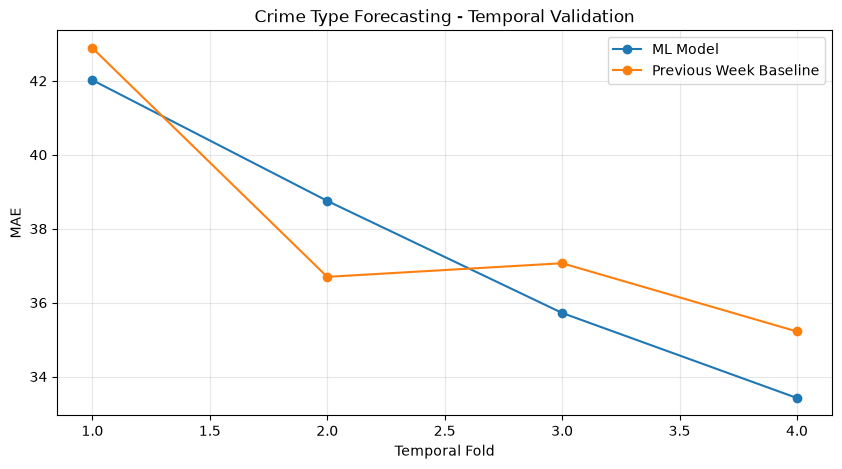

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    cv_type['fold'],
    cv_type['model_MAE'],
    marker='o',
    label='ML Model'
)

plt.plot(
    cv_type['fold'],
    cv_type['baseline_MAE'],
    marker='o',
    label='Previous Week Baseline'
)

plt.xlabel('Temporal Fold')
plt.ylabel('MAE')

plt.title(
    'Crime Type Forecasting - Temporal Validation'
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [42]:
final_type_model = HistGradientBoostingRegressor(
    loss='poisson',
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

final_type_model.fit(
    X_type,
    y_type
)

print("Final crime-type model trained ✅")

Final crime-type model trained ✅


In [43]:
last_week = (
    weekly_complete['week'].max()
)

next_week = (
    last_week
    + pd.Timedelta(days=7)
)

print("Last observed week:", last_week)
print("Forecast week:", next_week)

Last observed week: 2026-09-28 00:00:00
Forecast week: 2026-10-05 00:00:00


In [44]:
future_types = pd.DataFrame({
    'primary_type': top_types
})

future_types['week'] = next_week

future_types['type_code'] = (
    future_types['primary_type']
    .map(type_mapping)
)

In [45]:
future_types['week_of_year'] = (
    next_week.isocalendar().week
)

future_types['month'] = next_week.month
future_types['year'] = next_week.year

future_types['week_sin'] = np.sin(
    2 * np.pi
    * future_types['week_of_year']
    / 52
)

future_types['week_cos'] = np.cos(
    2 * np.pi
    * future_types['week_of_year']
    / 52
)

In [46]:
history_groups = {
    crime_type: group.sort_values('week')
    for crime_type, group
    in weekly_complete.groupby('primary_type')
}


def build_history_features(crime_type):

    values = (
        history_groups[crime_type]
        ['crime_count']
        .reset_index(drop=True)
    )

    return pd.Series({
        'lag_1': values.iloc[-1],
        'lag_2': values.iloc[-2],
        'lag_4': values.iloc[-4],
        'lag_8': values.iloc[-8],
        'lag_12': values.iloc[-12],
        'lag_52': values.iloc[-52],

        'rolling_4_mean':
            values.tail(4).mean(),

        'rolling_8_mean':
            values.tail(8).mean(),

        'rolling_12_mean':
            values.tail(12).mean(),

        'rolling_4_std':
            values.tail(4).std()
    })


In [47]:
future_history = (
    future_types['primary_type']
    .apply(build_history_features)
)

history_columns = [
    'lag_1',
    'lag_2',
    'lag_4',
    'lag_8',
    'lag_12',
    'lag_52',
    'rolling_4_mean',
    'rolling_8_mean',
    'rolling_12_mean',
    'rolling_4_std'
]

future_types[
    history_columns
] = future_history.values


In [48]:
future_types[
    features_type
].isnull().sum()

type_code          0
week_of_year       0
month              0
year               0
week_sin           0
week_cos           0
lag_1              0
lag_2              0
lag_4              0
lag_8              0
lag_12             0
lag_52             0
rolling_4_mean     0
rolling_8_mean     0
rolling_12_mean    0
rolling_4_std      0
dtype: int64

In [49]:
X_future_type = (
    future_types[
        features_type
    ]
)

future_types['predicted_crimes'] = (
    final_type_model.predict(
        X_future_type
    )
)

future_types['predicted_crimes'] = (
    future_types['predicted_crimes']
    .clip(lower=0)
)

In [50]:
future_types = (
    future_types
    .sort_values(
        'predicted_crimes',
        ascending=False
    )
    .reset_index(drop=True)
)

future_types['rank'] = (
    np.arange(
        1,
        len(future_types) + 1
    )
)

future_types[
    [
        'rank',
        'primary_type',
        'predicted_crimes'
    ]
]

,rank,primary_type,predicted_crimes
0,1,THEFT,741.720320
1,2,BATTERY,611.127901
2,3,CRIMINAL DAMAGE,376.687751
3,4,ASSAULT,346.511405
4,5,MOTOR VEHICLE THEFT,278.121550
5,6,OTHER OFFENSE,247.713857
6,7,BURGLARY,226.703056
7,8,DECEPTIVE PRACTICE,157.097061
8,9,ROBBERY,80.674041
9,10,WEAPONS VIOLATION,79.394166


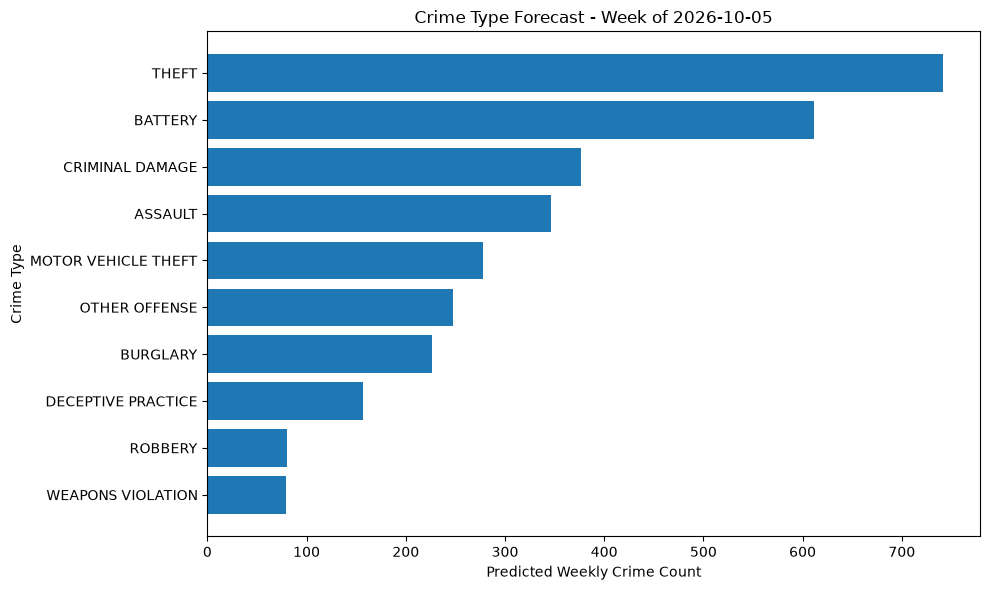

In [51]:
plot_data = (
    future_types
    .sort_values('predicted_crimes')
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    plot_data['primary_type'],
    plot_data['predicted_crimes']
)

plt.title(
    f'Crime Type Forecast - Week of '
    f'{next_week.date()}'
)

plt.xlabel(
    'Predicted Weekly Crime Count'
)

plt.ylabel(
    'Crime Type'
)

plt.tight_layout()
plt.show()

In [52]:
import joblib
import os

os.makedirs(
    "../models",
    exist_ok=True
)

joblib.dump(
    final_type_model,
    "../models/crime_type_forecast_model.joblib"
)

joblib.dump(
    features_type,
    "../models/crime_type_forecast_features.joblib"
)

joblib.dump(
    type_mapping,
    "../models/crime_type_mapping.joblib"
)

print("Crime-type forecasting model saved ✅")

Crime-type forecasting model saved ✅


In [53]:
future_types.to_csv(
    "../data/future_crime_types.csv",
    index=False
)

print("Future crime-type forecast saved ✅")

Future crime-type forecast saved ✅


In [54]:
api_crime_types = (
    future_types[
        [
            'rank',
            'week',
            'primary_type',
            'predicted_crimes'
        ]
    ]
    .copy()
)

api_crime_types[
    'predicted_crimes'
] = (
    api_crime_types[
        'predicted_crimes'
    ]
    .round(1)
)

api_crime_types.to_csv(
    "../data/api_crime_type_forecast.csv",
    index=False
)

api_crime_types

,rank,week,primary_type,predicted_crimes
0,1,2026-10-05,THEFT,741.7
1,2,2026-10-05,BATTERY,611.1
2,3,2026-10-05,CRIMINAL DAMAGE,376.7
3,4,2026-10-05,ASSAULT,346.5
4,5,2026-10-05,MOTOR VEHICLE THEFT,278.1
5,6,2026-10-05,OTHER OFFENSE,247.7
6,7,2026-10-05,BURGLARY,226.7
7,8,2026-10-05,DECEPTIVE PRACTICE,157.1
8,9,2026-10-05,ROBBERY,80.7
9,10,2026-10-05,WEAPONS VIOLATION,79.4


In [55]:
outputs = [
    "../models/crime_type_forecast_model.joblib",
    "../models/crime_type_forecast_features.joblib",
    "../models/crime_type_mapping.joblib",
    "../data/future_crime_types.csv",
    "../data/api_crime_type_forecast.csv"
]

for path in outputs:
    print(
        path,
        "→",
        os.path.exists(path)
    )

../models/crime_type_forecast_model.joblib → True
../models/crime_type_forecast_features.joblib → True
../models/crime_type_mapping.joblib → True
../data/future_crime_types.csv → True
../data/api_crime_type_forecast.csv → True


Conclusion
Weekly crime-type forecasting was performed for the most frequent crime categories.

Historical lag features, rolling statistics and seasonal temporal features were used to predict future weekly counts.

The HistGradientBoosting model slightly outperformed the previous-week baseline across temporal validation:

Average MAE: 37.48 vs 37.97
Average RMSE: 53.19 vs 53.76
Average R²: 0.9683 vs 0.9675
The improvement is modest, indicating that recent historical crime levels already provide a very strong forecasting signal.

The final model is therefore used as an aggregate short-term forecasting component rather than as a predictor of individual criminal events.